# Checking AI Responses


This notebook was created to check if the responses AI gave me were correct based on the DataBank_World_CO2_Emissions_kt.tsv file


# My code:

{'Country Name': 'Angola', 'Country Code': 'AGO', 'Region': 'Sub-Saharan Africa', 'Year': '2004', 'CO2 (kt)': '18,793.38'}
11127


,CO2 Emissions (kt),Percentage (%)
Region,,
Sub-Saharan Africa,713656.88,2.28
Latin America & Caribbean,1691634.80,5.40
South Asia,2197647.77,7.01
Middle East & North Africa,2304753.51,7.36
North America,5905450.47,18.85
Europe & Central Asia,6761346.65,21.58
East Asia & Pacific,11757194.06,37.52


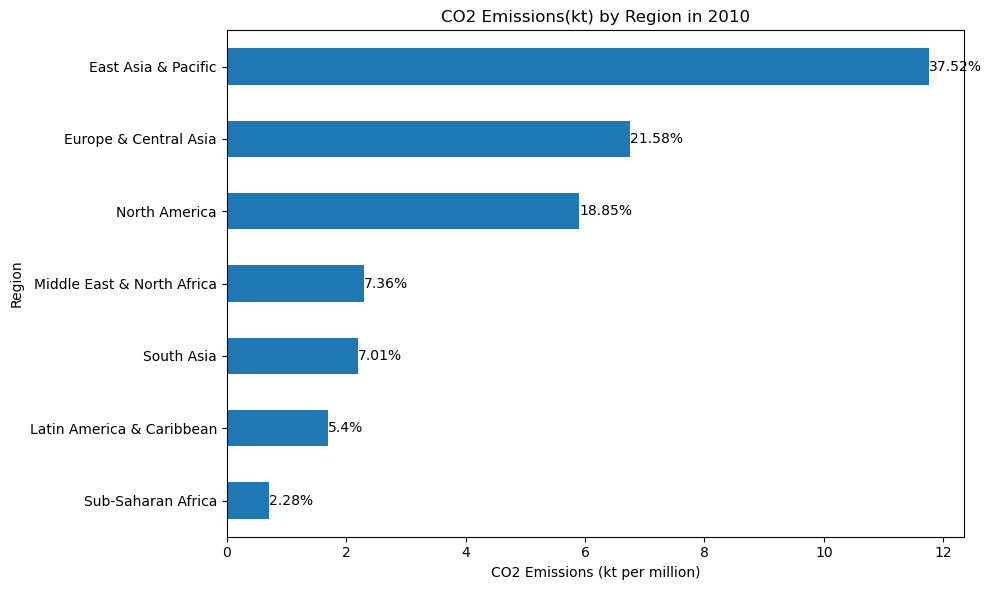

In [41]:
import pandas as pd
import matplotlib.pyplot as plt
import csv
import requests
from IPython.display import display
import math



def prepare_datasets(file_path):
    #From A2
    
    with open(file_path) as infile:
        reader = csv.DictReader(infile, delimiter='\t')
        list_of_dicts = [dict(r) for r in reader]
        
    return list_of_dicts


co2_emissions = prepare_datasets("DataBank_World_CO2_Emissions_kt.tsv")
print(co_emissions[200])
print(len(co_emissions))


df = pd.DataFrame(co2_emissions)
df.head()

df_2010 = df[df["Year"] == "2010"].copy()

df_2010["CO2 (kt)"] = pd.to_numeric(
    df_2010["CO2 (kt)"].str.replace(",", ""),
    errors="coerce"
)


#Rewritten and changed from A2
by_region = df_2010.groupby("Region")["CO2 (kt)"].sum()

co2_percentage = (by_region / by_region.sum() * 100).round(2)

co2_data = {
    "CO2 Emissions (kt)": by_region,
    "Percentage (%)": co2_percentage
}


co2_unsorted = pd.DataFrame(data=co2_data)

co2_table = co2_unsorted.sort_values(
    by="CO2 Emissions (kt)",
    ascending=True
)

co2_table["CO2 Emissions (kt)"] = co2_table["CO2 Emissions (kt)"].round(2)

display(co2_table)

# Create bar chart

ax = (co2_table["CO2 Emissions (kt)"]/ 1000000).plot.barh(
    figsize=(10, 6),
    xlabel="CO2 Emissions (kt per million)",
    ylabel="Region",
    legend=False
)
ax.ticklabel_format(axis="x", style="plain")

for i, percentage in enumerate(co2_table["Percentage (%)"]):
    ax.text(
        (co2_table["CO2 Emissions (kt)"]/ 1000000).iloc[i],
        i,
        f"{percentage}%",
        va="center",
        ha="left"
    )

plt.title("CO2 Emissions(kt) by Region in 2010")
plt.tight_layout()
plt.show()



